# Predicting Credit Card Fraud Using Transaction Features

---
embed-resources: true
echo: false
warning: false
message: false
---

## Introduction

Credit card fraud detection is a critical problem faced by financial institutions, as fraudulend transactions can result in significant financial losses and damage customer trust. Unlike many classification problems, fraud detection is particularly challenging due to extreme class imbalance and asymmetric costs. Fraudulent transactions are rare, but missing them (false negatives) can be far more costly than incorrectly flagging legitimate transactions (false positives). This report will investigates whether machine learning models can effectively identify fraudulent transactions using transaction data. The dataset consists of numerical features representing transaction characteristics, including transaction amount and anonymized principal components. The goal is to develop a model that balances precision and recall, ensuring fraudulent transactions are detected while minimizing unnecessary disruptions for legitimate users. 

## Methods

In [1]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
from joblib import dump
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, classification_report

### Data

In [2]:
# load data
fraud_train = pd.read_csv(
    "fraud-train.csv",
)
fraud_test = pd.read_csv(
    "fraud-test.csv",
)

The dataset contains information about credit card transactions. Each observation represents a single transaction and includes the following variables: 

| Variable | Type | Description |
|----------|------|-------------|
| Fraud | int64 | Status of the transaction. 1 indicates a fraudulent transaction and 0 indicates not fraud, a genuine transaction. |
| Amount | float64 | Amount (in dollars) of the transaction. |
| PC01 - PC28 | float64 | The 28 principal components that encode information such as location and type of purchase while preserving customer privacy. |

In [3]:
# summary statistics
fraud_train.shape

(54276, 30)

The count for fraudulent transaction and genuine transaction:

In [4]:
fraud_train["Fraud"].value_counts()

Fraud
0    53961
1      315
Name: count, dtype: int64

The percentage of fraudulent transaction and genuine transaction:

In [5]:
fraud_train["Fraud"].value_counts(normalize=True)

Fraud
0    0.994196
1    0.005804
Name: proportion, dtype: float64

The basic metrics for transaction amount: 

In [6]:
fraud_train["Amount"].describe()

count    54276.000000
mean        88.197903
std        241.535617
min          0.000000
25%          5.490000
50%         21.690000
75%         76.000000
max      10199.440000
Name: Amount, dtype: float64

The basic metrics of transaction amount for fraudulent transaciton and genuine transaction:

In [7]:
fraud_train["Amount"].describe()
fraud_train.groupby("Fraud")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Fraud,,,,,,,,
0,53961.0,88.065104,241.451144,0.0,5.5,21.80,75.97,10199.44
1,315.0,110.947016,254.978960,0.0,1.0,6.99,99.99,2125.87


My summary statistics show that the dataset contains 54,276 transactions and 29 features. I computed the count and proportion of fraudulent and legitimate transactions, finding that fraudulent transactions are extremely rare, accounting for only about 0.58% of the data. I also calculated the mean, standard deviation, and quartiles of transaction amounts to summarize their distribution. Additionally, I compared these statistics across fraudulent and legitimate transactions, observing that fraudulent transactions tend to have a higher average amount and greater variability than genuine transactions.

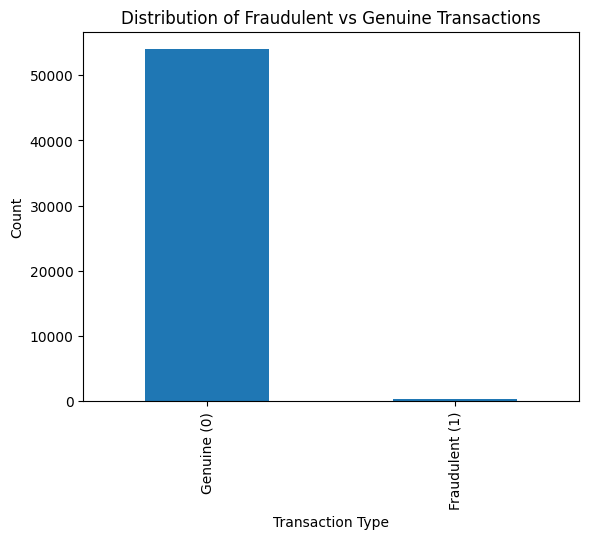

In [8]:
#| fig-cap: "Figure 1. Distribution of Genuine and Fraudulent Transactions in the Training Data"
# exploratory visualization
fraud_train["Fraud"].value_counts().plot(kind="bar")
plt.xticks([0, 1], ["Genuine (0)", "Fraudulent (1)"])
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.title("Distribution of Fraudulent vs Genuine Transactions")
plt.show()

### Models

In [9]:
# process data for ML
# create X and y for train
X_train = fraud_train.drop("Fraud", axis=1)
y_train = fraud_train["Fraud"]

# create X and y for test
X_test = fraud_test.drop("Fraud", axis=1)
y_test = fraud_test["Fraud"]

In [10]:
# train models
model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

The fraud detection task was treated as a binary classification problem, where the goal is to classify transactions as either fraudulent or genuine. A Random Forest classifier was used due to its ability to capture complex relationships in the data and perform well on structured datasets. The model was trained using 200 decision trees, allowing it to learn a diverse set of patterns from the training data. Each tree contributes to the final prediction, helping improve overall model stability and performance. The model was trained on the full training dataset and then used to make predictions on unseen test data to evaluate its ability to generalize. No additional preprocessing was required, as all features in the dataset are numerical and already suitable for modeling.

## Results

In [11]:
# report model metrics
y_pred = model.predict(X_test)

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Precision: {precision:.6f}")
print(f"Test Recall: {recall:.6f}")
print(f"Test F1 Score: {f1:.6f}")
print(f"Test Accuracy: {accuracy:.6f}")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Test Precision: 0.984848
Test Recall: 0.822785
Test F1 Score: 0.896552
Test Accuracy: 0.998895

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     13490
           1       0.98      0.82      0.90        79

    accuracy                           1.00     13569
   macro avg       0.99      0.91      0.95     13569
weighted avg       1.00      1.00      1.00     13569



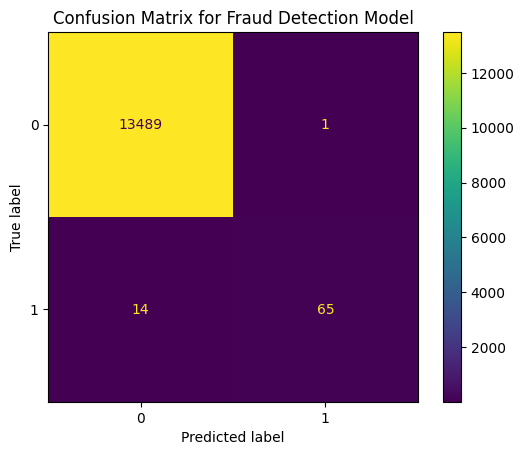

In [12]:
#| fig-cap: "Figure 1. Confusion Matrix for Fraud Detection Model on the Test Dataset"
# summary figure
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix for Fraud Detection Model")
plt.grid(False)
plt.show()

Overall, the results indicate that the model provides strong performance in identifying fraudulent transactions. The high precision demonstrates that the model rarely flags legitimate transactions as fraud, while the recall shows that it is able to detect the majority of fraudulent activity. Together, these results suggest that the model achieves an effective balance between minimizing false positives and capturing fraudulent transactions, making it well-suited for this classification task.

## Discussion

Based on the results presented above, I would recommend using this model in practice as part of a real-time credit card fraud detection system. The model demonstrates strong predictive performance, achieving high precision and recall, which are both critical in this application. The high precision ensures that transactions flagged as fraudulent are very likely to be actual fraud cases, reducing unnecessary disruptions for customers. At the same time, the relatively high recall indicates that the model is able to detect most fraudulent transactions, helping to minimize financial losses.

One important benefit of this model is that it can quickly and consistently evaluate transactions using available features at the time of purchase. This allows for real-time decision making, which is essential in fraud detection systems where transactions must be approved or denied within milliseconds. In practice, the model could be used to automatically flag suspicious transactions for further review or trigger additional authentication steps for the customer.

However, several limitations should also be considered. Although the recall is strong, the model does not detect all fraudulent transactions, meaning some fraud may still go unnoticed. Given the high cost associated with missed fraud, even a small number of false negatives can have significant consequences. Additionally, while the model minimizes false positives, incorrectly flagging legitimate transactions can still inconvenience customers and potentially reduce trust in the system.

The class imbalance present in the dataset also contributes to the difficulty of the problem. Because fraudulent transactions are rare, the model must carefully balance detecting fraud without over-predicting it. While the Random Forest model performs well under these conditions, further improvements could be made by tuning hyperparameters, adjusting classification thresholds, or exploring alternative models that better handle imbalanced data.

For these reasons, the model should not be used as a fully automated decision-maker without oversight. Instead, it would be most effective as part of a broader fraud detection system, where flagged transactions are reviewed or subjected to additional verification. This approach allows the model to assist in identifying high-risk transactions while maintaining a safeguard against potential errors.

Overall, the model demonstrates that machine learning can effectively identify fraudulent transactions using transaction-level data. While it is not perfect, it provides a strong foundation for a real-world fraud detection system that improves efficiency, reduces financial risk, and supports decision-making within a banking institution.